## Entrenamiento de algoritmos de clasificación

### Clasificación examen fisico

In [13]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from gensim.models import Word2Vec
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             cohen_kappa_score, roc_auc_score, confusion_matrix,
                             ConfusionMatrixDisplay)

stop_words = pd.read_excel(r"C:\Users\raultc\Documents\MAA\PROYECTO\proyecto final\stop words spanish.xlsx")
SPANISH_STOP_WORDS = set(stop_words.iloc[:, 0].str.lower().tolist())

In [ ]:



df_evaluate=pd.read_excel("C:/Users/raultc/Documents/MAA/PROYECTO/proyecto final/Audit HC (2).xlsx")
df_f = df_evaluate.dropna(subset=['Motivo de consulta', 'Enfermedad actual', 'Examen Físico', 'Diagnóstico'])

In [6]:

RANDOM_STATE = 42
CRITERIO     = "Examen Físico"     # columna del experto
N_FOLDS = 5
CV = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE)

# Tokenizador que conserva tildes y ñ
def tokenizar(texto):
    return re.findall(r"[a-záéíóúüñ]+", str(texto).lower())





df_exp = df_f.copy().reset_index(drop=True)
df_exp["caso"] = df_exp["caso"].astype(str)
df_exp["texto_sin_alterar"]  = df_exp["nota"].apply(lambda t: " ".join(tokenizar(t)))
df_exp["texto_sin_stopwords"] = df_exp["nota"].apply(
    lambda t: " ".join(w for w in tokenizar(t) if w not in SPANISH_STOP_WORDS))


y = df_exp[CRITERIO].astype(int).values
print(f"{CRITERIO}: {len(y)} notas | cumple: {(y == 1).sum()} | no cumple: {(y == 0).sum()}")

Examen Físico: 98 notas | cumple: 80 | no cumple: 18


In [7]:
df_exp

,caso,nota,num_words,stopword_ratio,Motivo de consulta,Enfermedad actual,Examen Físico,Diagnóstico,texto_sin_alterar,texto_sin_stopwords
0,S1137-66272008000500009-1,Se presenta un caso de una paciente de 26 años...,432.0,0.432558,1.0,1.0,1.0,1.0,se presenta un caso de una paciente de años qu...,se presenta caso de paciente de años que acude...
1,S1130-05582008000400008-3,Varón de 44 años ingresado por trauma facial. ...,69.0,0.362319,1.0,0.0,0.0,1.0,varón de años ingresado por trauma facial el e...,varón de años ingresado trauma facial estudio ...
2,S1130-01082008001100009-1,Mujer de 79 años sin antecedentes de interés q...,148.0,0.412162,1.0,1.0,1.0,1.0,mujer de años sin antecedentes de interés que ...,mujer de años antecedentes de interés que cons...
3,S0212-16112008000500014-1,Varón de 78 años que ingresa en Medicina Inter...,NaN,NaN,1.0,1.0,1.0,0.0,varón de años que ingresa en medicina interna ...,varón de años que ingresa medicina interna del...
4,S1130-01082007001100010-1,Mujer de 74 años cirrótica VHC asociada a hemo...,224.0,0.384615,0.0,1.0,0.0,1.0,mujer de años cirrótica vhc asociada a hemocro...,mujer de años cirrótica vhc asociada a hemocro...
...,...,...,...,...,...,...,...,...,...,...
93,S0365-66912011001000003-1,El primer caso es el de una niña de 9 años de ...,169.0,0.534591,1.0,1.0,1.0,0.0,el primer caso es el de una niña de años de ed...,primer caso de niña de años de edad que referí...
94,S0376-78922007000300006-3,"Varón de 20 años, pescador, sin antecedentes m...",118.0,0.456140,0.0,1.0,1.0,0.0,varón de años pescador sin antecedentes médico...,varón de años pescador antecedentes médicos de...
95,S1887-85712013000200013-1,"Paciente de 3 años (94 cm, 10 Kg), niña, afgan...",167.0,0.388535,1.0,1.0,1.0,0.0,paciente de años cm kg niña afgana con signos ...,paciente de años cm kg niña afgana signos de d...
96,S0212-71992006000900007-1,Varón de 51 años que acudió a las consultas de...,337.0,0.455357,1.0,1.0,1.0,1.0,varón de años que acudió a las consultas de de...,varón de años que acudió a consultas de dermat...


### Representaciones

- **BoW**: conteo de palabras.
- **TF-IDF**: conteo ponderado por lo rara que es cada palabra en el corpus.
- **W2V**: promedio de los vectores Word2Vec de las palabras de la nota.
- **W2V + TF-IDF**: promedio de los vectores Word2Vec ponderado por el peso TF-IDF de cada palabra.

Todas van dentro de un pipeline, así que en cada fold se entrenan **solo con las notas de train**

Notas del experto: 98 | cumple: 80 | no cumple: 18
✓ Sin números – BoW
✓ Sin números – TF-IDF
✓ Sin números – W2V
✓ Sin números – W2V + TF-IDF
✓ Con números – BoW
✓ Con números – TF-IDF
✓ Con números – W2V
✓ Con números – W2V + TF-IDF
✓ Número genérico – BoW
✓ Número genérico – TF-IDF
✓ Número genérico – W2V
✓ Número genérico – W2V + TF-IDF


F1_media  F1_desv  Recall_No_cumple  Acc_media
Tokenización    Representación                                                
Con números     TF-IDF             0.647    0.132             0.600      0.786
                W2V + TF-IDF       0.647    0.132             0.600      0.786
                BoW                0.636    0.210             0.533      0.788
Número genérico W2V + TF-IDF       0.630    0.189             0.500      0.796
Sin números     W2V                0.621    0.152             0.667      0.697
                TF-IDF             0.616    0.177             0.550      0.776
Número genérico TF-IDF             0.612    0.183             0.550      0.766
Sin números     W2V + TF-IDF       0.606    0.166             0.550      0.766
                BoW                0.605    0.178             0.500      0.777
Número genérico BoW                0.605    0.178             0.500      0.777
                W2V                0.600    0.076             0.667      0.675
Con números     W2V                0.483    0.135             0.467      0.594

Tokenización,Sin números,Con números,Número genérico
Representación,,,
BoW,0.605 ± 0.178,0.636 ± 0.210,0.605 ± 0.178
TF-IDF,0.616 ± 0.177,0.647 ± 0.132,0.612 ± 0.183
W2V,0.621 ± 0.152,0.483 ± 0.135,0.600 ± 0.076
W2V + TF-IDF,0.606 ± 0.166,0.647 ± 0.132,0.630 ± 0.189


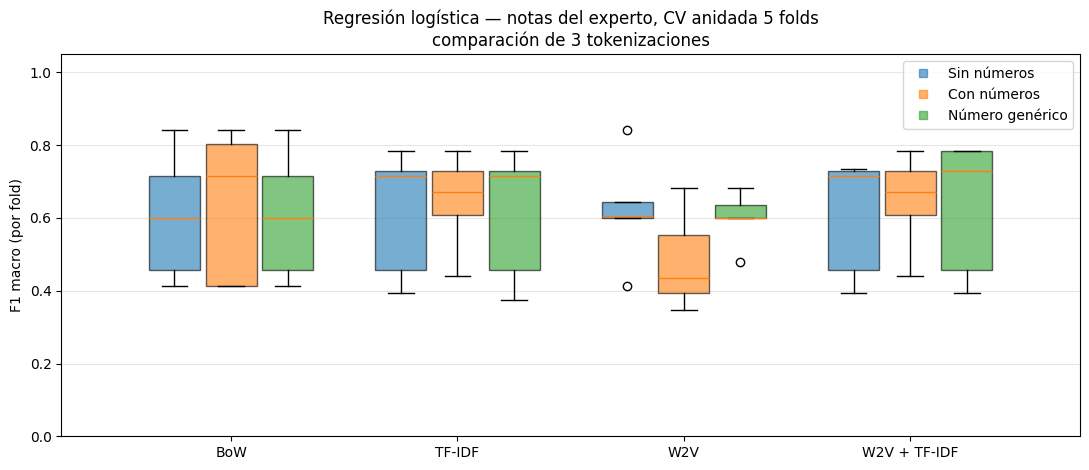

In [ ]:
# =====================================================================
# CLASIFICACIÓN — ¿Qué tokenización clasifica mejor?
# Notas del EXPERTO (df_exp) · Regresión logística (elastic net)
# Validación cruzada anidada, igual que la celda 10:
#   CV externo = 5 folds (mide F1) | CV interno = 3 folds (elige C y l1_ratio)
# 3 tokenizaciones × 4 representaciones
# =====================================================================
import re, unicodedata, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from gensim.models import Word2Vec
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.preprocessing import StandardScaler, MaxAbsScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import f1_score, recall_score, accuracy_score
from sklearn.exceptions import ConvergenceWarning

RANDOM_STATE = 42

# 1) Datos: notas y etiquetas del experto
datos = df_exp[df_exp["Examen Físico"].notna()].reset_index(drop=True)
y_exp = datos["Examen Físico"].astype(int).to_numpy()
print(f"Notas del experto: {len(y_exp)} | cumple: {(y_exp == 1).sum()} | no cumple: {(y_exp == 0).sum()}")

# 2) Las 3 tokenizaciones -> 3 columnas de texto
def _normalizar(texto):
    return unicodedata.normalize("NFC", str(texto)).lower()

def tok_sin_numeros(texto):
    return re.findall(r"[a-záéíóúüñ]+", _normalizar(texto))

def tok_con_numeros(texto):
    return re.findall(r"[a-záéíóúüñ]+|\d+", _normalizar(texto))

def tok_num_generico(texto):
    return re.findall(r"[a-záéíóúüñ]+", re.sub(r"\d+", " num ", _normalizar(texto)))

TOKENIZACIONES = {"Sin números": tok_sin_numeros,
                  "Con números": tok_con_numeros,
                  "Número genérico": tok_num_generico}

TEXTOS_TOK = {}
for nombre_tok, tok in TOKENIZACIONES.items():
    TEXTOS_TOK[nombre_tok] = datos["nota"].fillna("").apply(lambda t: " ".join(tok(t)))

# 3) Representaciones (misma configuración que REPRESENTACIONES).
#    W2V con su propio .split(): no depende de la función global `tokenizar`.
class W2VClf(BaseEstimator, TransformerMixin):
    def __init__(self, vector_size=100, window=5, min_count=2, seed=42):
        self.vector_size, self.window = vector_size, window
        self.min_count, self.seed = min_count, seed

    def fit(self, X, y=None):
        self.w2v_ = Word2Vec([str(t).split() for t in X], vector_size=self.vector_size,
                             window=self.window, min_count=self.min_count,
                             seed=self.seed, workers=1)
        return self

    def transform(self, X):
        filas = []
        for t in X:
            vecs = [self.w2v_.wv[p] for p in str(t).split() if p in self.w2v_.wv]
            filas.append(np.mean(vecs, axis=0) if vecs else np.zeros(self.vector_size))
        return np.vstack(filas)

REPS_CLF = {
    "BoW":          lambda: CountVectorizer(min_df=2),
    "TF-IDF":       lambda: TfidfVectorizer(ngram_range=(1, 2), min_df=2),
    "W2V":          lambda: W2VClf(),
    "W2V + TF-IDF": lambda: FeatureUnion([
        ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=2)),
        ("w2v",   W2VClf()),
    ]),
}

# 4) Regresión logística + búsqueda de hiperparámetros (igual que la celda 10)
GRILLA = {
    "clf__C": np.logspace(-3, 2, 11),
    "clf__l1_ratio": [0.0, 0.5, 1.0],     # 0 = L2, 1 = L1
}

def pipeline_logistica(nombre_rep):
    densa = nombre_rep == "W2V"
    return Pipeline([
        ("rep", REPS_CLF[nombre_rep]()),
        ("esc", StandardScaler() if densa else MaxAbsScaler()),
        ("clf", LogisticRegression(solver="saga", penalty="elasticnet", tol=1e-4,
                                   class_weight="balanced", max_iter=5000,
                                   random_state=RANDOM_STATE)),
    ])

cv_externo = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_interno = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

# 5) Validación cruzada anidada: 3 tokenizaciones × 4 representaciones
#    (los mismos folds para todas, así la comparación es justa)
folds = list(cv_externo.split(datos, y_exp))
filas_clf, pred_tok = [], {}

with warnings.catch_warnings():
    warnings.simplefilter("ignore", ConvergenceWarning)
    warnings.simplefilter("ignore", FutureWarning)
    for nombre_tok, textos in TEXTOS_TOK.items():
        for nombre_rep in REPS_CLF:
            pred_oof = np.empty(len(y_exp), dtype=int)
            for i, (tr, te) in enumerate(folds):
                busqueda = GridSearchCV(pipeline_logistica(nombre_rep), GRILLA,
                                        scoring="f1_macro", cv=cv_interno, n_jobs=-1)
                busqueda.fit(textos.iloc[tr], y_exp[tr])
                y_pred = busqueda.predict(textos.iloc[te])
                pred_oof[te] = y_pred
                filas_clf.append({
                    "Tokenización": nombre_tok,
                    "Representación": nombre_rep,
                    "Fold": i,
                    "F1 macro": f1_score(y_exp[te], y_pred, average="macro"),
                    "Recall No cumple": recall_score(y_exp[te], y_pred, pos_label=0),
                    "Accuracy": accuracy_score(y_exp[te], y_pred),
                    "C": busqueda.best_params_["clf__C"],
                    "l1_ratio": busqueda.best_params_["clf__l1_ratio"],
                })
            pred_tok[(nombre_tok, nombre_rep)] = pred_oof
            print(f"✓ {nombre_tok} – {nombre_rep}")

df_folds_tok = pd.DataFrame(filas_clf)

# 6) Resultados
resumen_tok = (df_folds_tok
    .groupby(["Tokenización", "Representación"], sort=False)
    .agg(F1_media=("F1 macro", "mean"), F1_desv=("F1 macro", "std"),
         Recall_No_cumple=("Recall No cumple", "mean"), Acc_media=("Accuracy", "mean"))
    .sort_values("F1_media", ascending=False)
    .round(3))
display(resumen_tok)

# Tabla compacta: F1 macro (media ± desv) por representación y tokenización
tabla_f1 = (df_folds_tok.groupby(["Representación", "Tokenización"], sort=False)["F1 macro"]
            .agg(lambda s: f"{s.mean():.3f} ± {s.std():.3f}")
            .unstack()[list(TOKENIZACIONES)])
display(tabla_f1)

# Boxplot del F1 por fold
fig, ax = plt.subplots(figsize=(11, 4.8))
reps = list(REPS_CLF)
ancho = 0.25
for k, nombre_tok in enumerate(TOKENIZACIONES):
    datos_box = [df_folds_tok.query("Tokenización == @nombre_tok and Representación == @r")["F1 macro"]
                 for r in reps]
    pos = np.arange(len(reps)) + (k - 1) * ancho
    bp = ax.boxplot(datos_box, positions=pos, widths=ancho * 0.9, patch_artist=True)
    for caja in bp["boxes"]:
        caja.set_facecolor(f"C{k}"); caja.set_alpha(0.6)
    ax.plot([], [], "s", color=f"C{k}", alpha=0.6, label=nombre_tok)
ax.set_xticks(np.arange(len(reps))); ax.set_xticklabels(reps)
ax.set(ylabel="F1 macro (por fold)", ylim=(0, 1.05),
       title="Regresión logística — notas del experto, CV anidada 5 folds\n"
             "comparación de 3 tokenizaciones")
ax.legend(); ax.grid(alpha=0.3, axis="y")
plt.tight_layout()
plt.savefig("f1_tokenizaciones_logistica.png", dpi=200, bbox_inches="tight")
plt.show()

In [8]:
import numpy as np
from gensim.models import Word2Vec
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.pipeline import FeatureUnion

def tokenizar(texto):
    return str(texto).lower().split()

class W2VPromedio(BaseEstimator, TransformerMixin):
    """Entrena Word2Vec con los textos de train y representa cada nota
    como el promedio de los vectores de sus palabras."""
    def __init__(self, vector_size=100, window=5, min_count=2, seed=42):
        self.vector_size = vector_size
        self.window = window
        self.min_count = min_count
        self.seed = seed

    def fit(self, X, y=None):
        frases = [tokenizar(t) for t in X]
        self.w2v_ = Word2Vec(frases, vector_size=self.vector_size, window=self.window,
                             min_count=self.min_count, seed=self.seed, workers=1)
        return self

    def transform(self, X):
        filas = []
        for t in X:
            vecs = [self.w2v_.wv[p] for p in tokenizar(t) if p in self.w2v_.wv]
            filas.append(np.mean(vecs, axis=0) if vecs else np.zeros(self.vector_size))
        return np.vstack(filas)

REPRESENTACIONES = {
    "BoW":        lambda: CountVectorizer(min_df=2),
    "TF-IDF":     lambda: TfidfVectorizer(ngram_range=(1, 2), min_df=2),
    "W2V":        lambda: W2VPromedio(),
    "W2V + TF-IDF": lambda: FeatureUnion([
        ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=2)),
        ("w2v",   W2VPromedio()),
    ]),
}

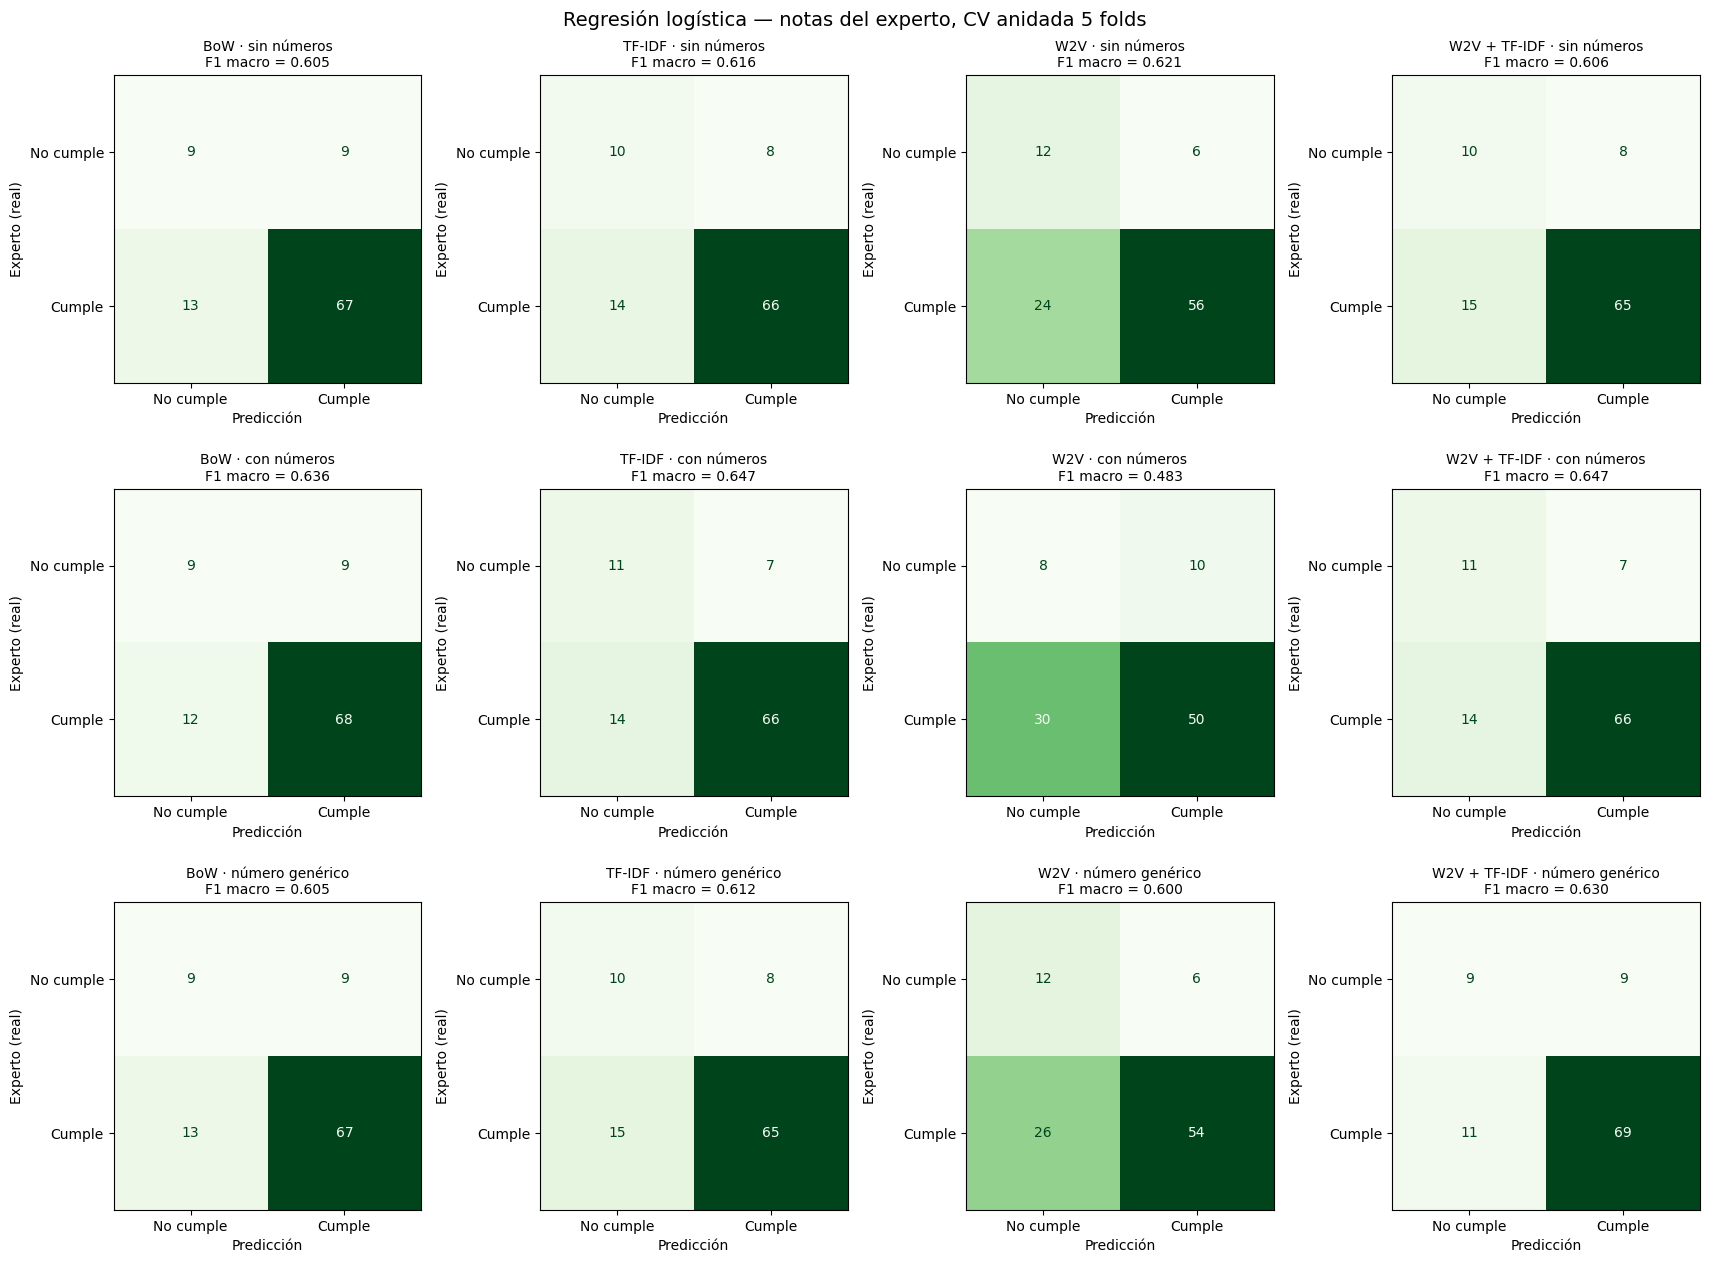

In [29]:
# =====================================================================
# Matrices de confusión — 3 tokenizaciones × 4 representaciones
# Predicciones out-of-fold de la CV anidada (cada nota se predice una vez,
# cuando estaba en el fold de test)
# =====================================================================
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

n_filas, n_cols = len(TOKENIZACIONES), len(REPS_CLF)
fig, axes = plt.subplots(n_filas, n_cols, figsize=(4.3 * n_cols, 4.3 * n_filas), squeeze=False)

for fila_ax, nombre_tok in zip(axes, TOKENIZACIONES):
    for ax, nombre_rep in zip(fila_ax, REPS_CLF):
        cm = confusion_matrix(y_exp, pred_tok[(nombre_tok, nombre_rep)], labels=[0, 1])
        f1 = resumen_tok.loc[(nombre_tok, nombre_rep), "F1_media"]
        ConfusionMatrixDisplay(cm, display_labels=["No cumple", "Cumple"]).plot(
            ax=ax, cmap="Greens", colorbar=False, values_format="d")
        ax.set_title(f"{nombre_rep} · {nombre_tok.lower()}\nF1 macro = {f1:.3f}", fontsize=10)
        ax.set_xlabel("Predicción")
        ax.set_ylabel("Experto (real)")

plt.suptitle("Regresión logística — notas del experto, CV anidada 5 folds", fontsize=14)
plt.tight_layout()
plt.savefig("matrices_confusion_tokenizaciones.png", dpi=200, bbox_inches="tight")
plt.show()

In [10]:
# =====================================================================
# CELDA 1 — Revisar la dimensión de los vectores de cada representación
# Pégala después de la celda donde defines REPRESENTACIONES y clasificador().
# Mide los vectores DENTRO de cada fold (solo con las notas de train),
# que es exactamente lo que recibe la regresión logística.
# =====================================================================
from scipy import sparse
from collections import Counter

TEXTOS = {"Con stopwords": "texto_sin_alterar", "sin stopwords": "texto_sin_stopwords"}

def medir_vectores(rep, textos):
    """Ajusta la representación y devuelve (n_notas, n_dimensiones, densidad, activas_por_nota)."""
    X = rep.fit_transform(textos)
    n, d = X.shape
    if sparse.issparse(X):
        densidad = X.nnz / (n * d)
        activas = X.getnnz(axis=1).mean()
    else:
        densidad = np.count_nonzero(X) / X.size
        activas = np.count_nonzero(X, axis=1).mean()
    return n, d, densidad, activas

filas_dim = []
for nombre_texto, col_texto in TEXTOS.items():
    for nombre_rep, crear_rep in REPRESENTACIONES.items():
        res = np.array([medir_vectores(crear_rep(), df_exp[col_texto].iloc[tr])
                        for tr, _ in CV.split(df_exp[col_texto], y)])
        n_train, dims = res[:, 0].mean(), res[:, 1]
        filas_dim.append({
            "Texto": nombre_texto,
            "Representación": nombre_rep,
            "Notas train (por fold)": int(n_train),
            "Dimensiones (media)": int(dims.mean()),
            "Dim. mín–máx entre folds": f"{int(dims.min())}–{int(dims.max())}",
            "Dimensiones / notas": round(dims.mean() / n_train, 1),
            "% celdas ≠ 0": round(res[:, 2].mean() * 100, 1),
            "Dimensiones activas por nota": int(res[:, 3].mean()),
        })

df_dim = pd.DataFrame(filas_dim)
display(df_dim)

# Contexto: cuántas notas hay por clase en train (la clase minoritaria es la que limita)
n_min = int((y == 0).sum() * (N_FOLDS - 1) / N_FOLDS)
print(f"Clase minoritaria ('No cumple') en train por fold: ~{n_min} notas")



,Texto,Representación,Notas train (por fold),Dimensiones (media),Dim. mín–máx entre folds,Dimensiones / notas,% celdas ≠ 0,Dimensiones activas por nota
0,Con stopwords,BoW,78,2077,2058–2108,26.5,7.0,146
1,Con stopwords,TF-IDF,78,4529,4445–4618,57.8,5.8,260
2,Con stopwords,W2V,78,100,100–100,1.3,100.0,100
3,Con stopwords,W2V + TF-IDF,78,4629,4545–4718,59.1,7.8,360
4,sin stopwords,BoW,78,2006,1984–2039,25.6,6.4,127
5,sin stopwords,TF-IDF,78,3587,3516–3672,45.8,5.5,196
6,sin stopwords,W2V,78,100,100–100,1.3,100.0,100
7,sin stopwords,W2V + TF-IDF,78,3687,3616–3772,47.0,8.0,296


Clase minoritaria ('No cumple') en train por fold: ~14 notas


#### Los numeros pierden información??


- Elegir el clasificador

In [12]:
from functools import partial
from sklearn.linear_model import LogisticRegression

clasificador = partial(
    LogisticRegression,
    tol=1e-4,                 # saga converge lento con BoW/TF-IDF
    class_weight="balanced",   # compensa el desbalance (~14 "No cumple" por fold)
    max_iter=5000,             # saga converge lento, sobre todo con BoW/TF-IDF
    random_state=RANDOM_STATE,
)

In [13]:
# =====================================================================
# CELDA 2 — Parametrizar la regresión logística por representación
# Validación cruzada anidada: CV externo = tu CV; CV interno = búsqueda de C y l1_ratio
# =====================================================================
from tempfile import mkdtemp
from shutil import rmtree
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, MaxAbsScaler
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import f1_score, recall_score, accuracy_score

GRILLA = {
    "clf__C": np.logspace(-3, 2, 11),
    "clf__l1_ratio": [0.0, 0.5, 1.0],   # 0 = L2, 1 = L1
}

def construir_pipeline(nombre_rep, crear_rep, cache):
    densa = nombre_rep == "W2V"
    return Pipeline([
        ("rep", crear_rep()),
        ("esc", StandardScaler() if densa else MaxAbsScaler()),
        ("clf", clasificador(solver="saga", penalty="elasticnet")),
    ], memory=cache)

y = np.asarray(y)
cv_interno = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
cache = mkdtemp()

filas, predicciones = [], {}
for nombre_texto, col_texto in TEXTOS.items():
    textos = df_exp[col_texto]
    for nombre_rep, crear_rep in REPRESENTACIONES.items():
        pred_oof = np.empty(len(y), dtype=int)
        for i, (tr, te) in enumerate(CV.split(textos, y)):
            busqueda = GridSearchCV(
                construir_pipeline(nombre_rep, crear_rep, cache), GRILLA,
                scoring="f1_macro", cv=cv_interno, n_jobs=1,
            )
            busqueda.fit(textos.iloc[tr], y[tr])
            y_pred = busqueda.predict(textos.iloc[te])
            pred_oof[te] = y_pred
            filas.append({
                "Texto": nombre_texto,
                "Representación": nombre_rep,
                "Fold": i,
                "F1 macro test": f1_score(y[te], y_pred, average="macro"),
                "Recall test": recall_score(y[te], y_pred),      # recall de "Cumple" (1)
                "Accuracy test": accuracy_score(y[te], y_pred),
            })
        predicciones[(nombre_texto, nombre_rep)] = pred_oof
        print(f"✓ {nombre_texto} – {nombre_rep}")

rmtree(cache)
df_folds = pd.DataFrame(filas)

resumen = (df_folds
    .groupby(["Texto", "Representación"], sort=False)
    .agg(F1_media=("F1 macro test", "mean"),
         Recall_Cumple=("Recall test", "mean"),
         Acc_media=("Accuracy test", "mean"),
    )
    .sort_values("F1_media", ascending=False)
    .round(3))
display(resumen)

c:\Users\biacus\.conda\envs\clinicaus\lib\site-packages\sklearn\linear_model\_sag.py:349: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\biacus\.conda\envs\clinicaus\lib\site-packages\sklearn\linear_model\_sag.py:349: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\biacus\.conda\envs\clinicaus\lib\site-packages\sklearn\linear_model\_sag.py:349: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\biacus\.conda\envs\clinicaus\lib\site-packages\sklearn\linear_model\_sag.py:349: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\biacus\.conda\envs\clinicaus\lib\site-packages\sklearn\linear_model\_sag.py:349: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\biacus\.conda\envs\clinicaus\lib\sit

✓ Con stopwords – BoW


c:\Users\biacus\.conda\envs\clinicaus\lib\site-packages\sklearn\linear_model\_sag.py:349: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\biacus\.conda\envs\clinicaus\lib\site-packages\sklearn\linear_model\_sag.py:349: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\biacus\.conda\envs\clinicaus\lib\site-packages\sklearn\linear_model\_sag.py:349: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\biacus\.conda\envs\clinicaus\lib\site-packages\sklearn\linear_model\_sag.py:349: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\biacus\.conda\envs\clinicaus\lib\site-packages\sklearn\linear_model\_sag.py:349: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\biacus\.conda\envs\clinicaus\lib\sit

✓ Con stopwords – TF-IDF


c:\Users\biacus\.conda\envs\clinicaus\lib\site-packages\sklearn\linear_model\_sag.py:349: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\biacus\.conda\envs\clinicaus\lib\site-packages\sklearn\linear_model\_sag.py:349: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\biacus\.conda\envs\clinicaus\lib\site-packages\sklearn\linear_model\_sag.py:349: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\biacus\.conda\envs\clinicaus\lib\site-packages\sklearn\linear_model\_sag.py:349: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\biacus\.conda\envs\clinicaus\lib\site-packages\sklearn\linear_model\_sag.py:349: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\biacus\.conda\envs\clinicaus\lib\sit

✓ Con stopwords – W2V


... (7 outputs left out)

✓ sin stopwords – W2V


c:\Users\biacus\.conda\envs\clinicaus\lib\site-packages\sklearn\linear_model\_sag.py:349: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\biacus\.conda\envs\clinicaus\lib\site-packages\sklearn\linear_model\_sag.py:349: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\biacus\.conda\envs\clinicaus\lib\site-packages\sklearn\linear_model\_sag.py:349: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\biacus\.conda\envs\clinicaus\lib\site-packages\sklearn\linear_model\_sag.py:349: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\biacus\.conda\envs\clinicaus\lib\site-packages\sklearn\linear_model\_sag.py:349: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\biacus\.conda\envs\clinicaus\lib\sit

✓ sin stopwords – W2V + TF-IDF


F1_media  Recall_Cumple  Acc_media
Texto         Representación                                    
sin stopwords BoW                0.642          0.812      0.767
Con stopwords W2V                0.621          0.700      0.697
              TF-IDF             0.616          0.825      0.776
              W2V + TF-IDF       0.606          0.812      0.766
              BoW                0.605          0.838      0.777
sin stopwords W2V + TF-IDF       0.558          0.838      0.746
              W2V                0.486          0.675      0.614
              TF-IDF             0.482          0.838      0.715

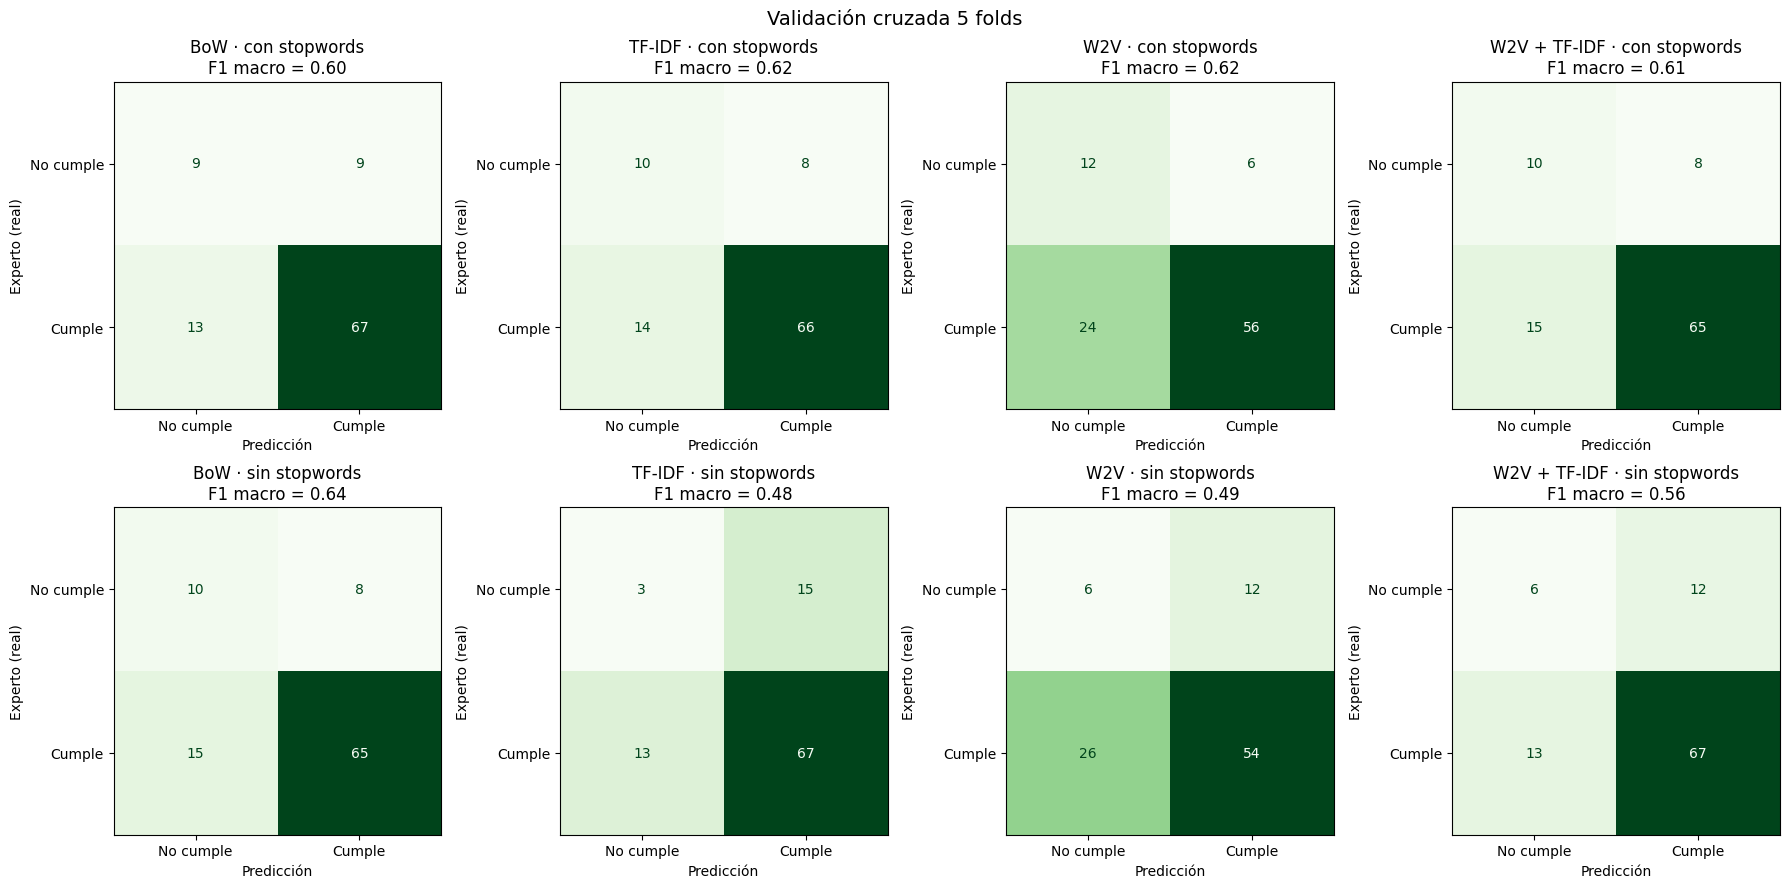

In [14]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

n_filas, n_cols = len(TEXTOS), len(REPRESENTACIONES)
fig, axes = plt.subplots(n_filas, n_cols, figsize=(4.5 * n_cols, 4.5 * n_filas), squeeze=False)

for fila_ax, nombre_texto in zip(axes, TEXTOS):
    for ax, nombre_rep in zip(fila_ax, REPRESENTACIONES):
        cm = confusion_matrix(y, predicciones[(nombre_texto, nombre_rep)], labels=[0, 1])
        f1 = resumen.loc[(nombre_texto, nombre_rep), "F1_media"]
        ConfusionMatrixDisplay(cm, display_labels=["No cumple", "Cumple"]).plot(
            ax=ax, cmap="Greens", colorbar=False, values_format="d")
        ax.set_title(f"{nombre_rep} · {nombre_texto.lower()}\nF1 macro = {f1:.2f}")
        ax.set_xlabel("Predicción")
        ax.set_ylabel("Experto (real)")

plt.suptitle(f"Validación cruzada {CV.get_n_splits()} folds", fontsize=14)
plt.tight_layout()
plt.show()

## Conclusiones: efecto de los números en las representaciones y en la clasificación del examen físico


### 2. Cómo afectan los números a la clasificación del examen físico

**Experimento:** regresión logística (elastic net, `class_weight="balanced"`) con validación cruzada anidada de 5 folds, entrenada y evaluada sobre las 98 notas del experto (80 cumple / 18 no cumple). Se usaron los mismos folds para las 12 combinaciones, así que solo cambia la tokenización.

**F1 macro (media ± desviación entre folds)**

| Representación | Sin números | Con números | Número genérico |
|---|---|---|---|
| BoW | 0.605 ± 0.178 | **0.636 ± 0.210** | 0.605 ± 0.178 |
| TF-IDF | 0.616 ± 0.177 | **0.647 ± 0.132** | 0.612 ± 0.183 |
| W2V | **0.621 ± 0.152** | 0.483 ± 0.135 | 0.600 ± 0.076 |
| W2V + TF-IDF | 0.606 ± 0.166 | **0.647 ± 0.132** | 0.630 ± 0.189 |

**Matrices de confusión: notas "No cumple" detectadas (de 18) / falsas alarmas (notas "Cumple" marcadas como "No cumple")**

| Representación | Sin números | Con números | Número genérico |
|---|---|---|---|
| BoW | 9 (50 %) / 13 | 9 (50 %) / 12 | 9 (50 %) / 13 |
| TF-IDF | 10 (56 %) / 14 | **11 (61 %) / 14** | 10 (56 %) / 15 |
| W2V | 12 (67 %) / 24 | 8 (44 %) / 30 | 12 (67 %) / 26 |
| W2V + TF-IDF | 10 (56 %) / 15 | **11 (61 %) / 14** | 9 (50 %) / 11 |

**Hallazgos**

1. **Conservar los números mejora ligeramente las representaciones basadas en conteos.** El F1 sube unos 0.03 en BoW y TF-IDF y unos 0.04 en W2V + TF-IDF. Las mejores combinaciones son **TF-IDF con números** y **W2V + TF-IDF con números** (F1 = 0.647), que además tienen la menor desviación entre las mejores (0.132) y detectan 11 de 18 notas "No cumple".
2. **TF-IDF y W2V + TF-IDF con números dan exactamente el mismo resultado** (mismas predicciones y mismo F1). Esto indica que, al combinarlas, la regresión se apoya en la parte TF-IDF y la parte W2V no aporta.
3. **W2V empeora mucho con números** (0.621 → 0.483) y genera más falsas alarmas (30). Con solo unas 78 notas de entrenamiento por fold, Word2Vec no tiene texto suficiente para aprender buenos vectores, y los números (muchos valores distintos, cada uno poco frecuente) agregan tokens con vectores ruidosos que diluyen el promedio. El W2V del experimento de similitud se entrenó con 899 notas y por eso sí se comportó bien.
4. **Número genérico prácticamente no cambia el resultado frente a sin números.** En BoW las predicciones son idénticas (0.605). Saber que hay un valor, sin saber cuál, no ayuda a este clasificador. Lo que aporta es el valor concreto o la combinación de término y número (TF-IDF con bigramas como "ta 120" o "fc 88").
5. **Control de consistencia:** "BoW · sin números" (0.605) coincide con "BoW · con stopwords" de la comparación inicial (0.605), porque es la misma configuración. Esto confirma que el experimento reproduce el resultado anterior.

**Precaución al interpretar.** Las diferencias entre tokenizaciones (≈ 0.03–0.04) son menores que la desviación entre folds (0.13–0.21). Con 98 notas y solo 18 "No cumple", la mejora equivale a detectar 1 nota "No cumple" más (10 → 11 en TF-IDF). La tendencia es consistente en tres de las cuatro representaciones, pero no es una diferencia estadísticamente concluyente.

### 3. Conclusión general

- La tokenización actual (`texto_sin_alterar`) **elimina toda la información numérica** (edad, TA, FC, temperatura). Las cuatro representaciones quedan ciegas a esos valores.
- **Conservar los números** hace que las representaciones los distingan: TF-IDF es la más sensible (≈ 21 % del cambio que produce cambiar la frase entera) y W2V la menos (≈ 2 %).
- En la clasificación del examen físico, conservar los números **mejora ligeramente** BoW, TF-IDF y W2V + TF-IDF, y **perjudica** a W2V cuando hay pocas notas de entrenamiento.
- **Recomendación:** usar **TF-IDF con números** como representación, y confirmar la mejora con el protocolo final (entrenar con las 899 notas del LLM y evaluar contra el experto en validación), porque con 98 notas la diferencia todavía está dentro de la variabilidad entre folds.


## Entrenamiento del mejor modelo

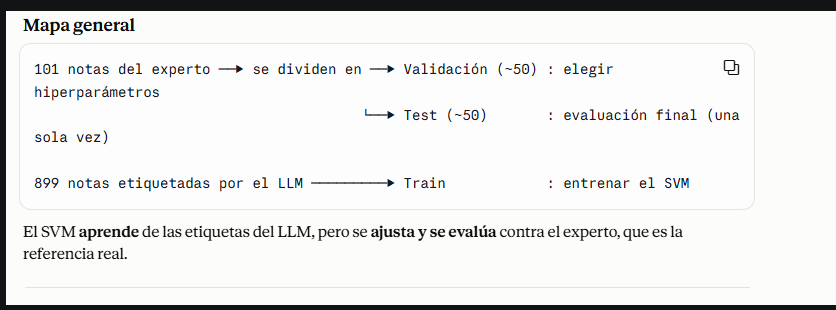

### Experimentos 


In [15]:
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import train_test_split, ParameterGrid
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import SVC
from sklearn.base import clone
from sklearn.metrics import (f1_score, recall_score, accuracy_score,
                             classification_report, ConfusionMatrixDisplay)

CRIT = "examen_fisico"

In [16]:
df_exp = pd.read_excel(r"C:\Users\raultc\Documents\MAA\PROYECTO\proyecto final\Audit HC (2).xlsx", sheet_name="Sheet1")
df_exp["caso"] = df_exp["caso"].astype(str)

Sesión restaurada.


In [4]:
df_exp

,caso,nota,num_words,stopword_ratio,Motivo de consulta,Enfermedad actual,Examen Físico,Diagnóstico
0,S1137-66272008000500009-1,Se presenta un caso de una paciente de 26 años...,432.0,0.432558,1.0,1.0,1.0,1.0
1,S1130-05582008000400008-3,Varón de 44 años ingresado por trauma facial. ...,69.0,0.362319,1.0,0.0,0.0,1.0
2,S1130-01082008001100009-1,Mujer de 79 años sin antecedentes de interés q...,148.0,0.412162,1.0,1.0,1.0,1.0
3,S0212-16112008000500014-1,Varón de 78 años que ingresa en Medicina Inter...,NaN,NaN,1.0,1.0,1.0,0.0
4,S1130-01082007001100010-1,Mujer de 74 años cirrótica VHC asociada a hemo...,224.0,0.384615,0.0,1.0,0.0,1.0
...,...,...,...,...,...,...,...,...
992,S1130-01082009000700016-1,Presentamos el caso de un paciente de 77 años ...,251.0,0.483607,NaN,NaN,NaN,NaN
993,S0210-48062009000300013-3,Varón de 74 años\nAntecedentes personales: HTA...,146.0,0.355072,NaN,NaN,NaN,NaN
994,S0004-06142006000900009-1,Paciente de 26 años que es remitido desde las ...,269.0,0.470149,NaN,NaN,NaN,NaN
995,S1130-01082005001100016-1,Mujer de 59 años sin antecedentes de interés q...,281.0,0.418251,NaN,NaN,NaN,NaN


In [5]:
COL_EXP = "Examen Físico"

# Si alguna nota se usó como ejemplo few-shot, se excluye de la evaluación
IDS_EJEMPLOS = set()          # p. ej. {"12", "45"}
df_exp = df_exp[~df_exp["caso"].isin(IDS_EJEMPLOS)]
df_exp = df_exp[df_exp[COL_EXP].notna()]

print("Notas del experto:", len(df_exp))
print(df_exp[COL_EXP].value_counts())

Notas del experto: 98
Examen Físico
1.0    80
0.0    18
Name: count, dtype: int64


### Dividir las notas del experto en validación y test

In [6]:
df_val, df_test = train_test_split(
    df_exp,
    test_size=0.5,
    stratify=df_exp[COL_EXP],
    random_state=42,
)

print("Validación:", df_val[COL_EXP].value_counts().to_dict())
print("Test:      ", df_test[COL_EXP].value_counts().to_dict())

# Guarda la división para que siempre sea la misma
df_val[["caso"]].to_csv("ids_validacion.csv", index=False)
df_test[["caso"]].to_csv("ids_test.csv", index=False)

Validación: {1.0: 40, 0.0: 9}
Test:       {1.0: 40, 0.0: 9}


### Cargar las 899 notas etiquetadas por el LLM

utilizare 899 train que salieron del LLM para el val y test se usaran 98 del experto

In [7]:
df_fewshot = pd.read_csv(r"C:\Users\raultc\Documents\MAA\PROYECTO\proyecto final\criterios_auditoria_fewshot_por_criterio.csv")

In [8]:
df_fewshot

,caso,motivo_consulta,motivo_consulta_razon,enfermedad_actual,enfermedad_actual_razon,examen_fisico,examen_fisico_razon,diagnostico,diagnostico_razon
0,S1137-66272008000500009-1,1,La paciente acude a consulta específicamente p...,1,Se describe un cuadro clínico con dolor en la ...,1,Se reportan hallazgos de la exploración física...,1,Se establece un diagnóstico claro de condrobla...
1,S1130-05582008000400008-3,1,"El ingreso se menciona por trauma facial, lo q...",0,El caso describe un evento aislado de trauma f...,0,No se reportan hallazgos de la exploración fís...,1,Se establece un diagnóstico claro de quiste ra...
2,S1130-01082008001100009-1,1,La paciente consultó específicamente por diarr...,1,Se describe un cuadro clínico en evolución con...,1,Se reporta una exploración física que incluye ...,1,Se establece claramente el diagnóstico de hepa...
3,S0212-16112008000500014-1,1,El paciente ingresa refiriendo aumento en el n...,1,Se describe un cuadro clínico en evolución con...,1,Se reportan hallazgos de la exploración física...,1,Se establece un diagnóstico de infección por C...
4,S1130-01082007001100010-1,0,El texto describe la condición y el tratamient...,1,Se describe un cuadro clínico en evolución con...,1,Se reportan hallazgos de la ecografía abdomina...,0,Se menciona el diagnóstico de encefalopatía he...
...,...,...,...,...,...,...,...,...,...
992,S1130-01082009000700016-1,1,El paciente acudió para la realización de una ...,1,Se describe un cuadro clínico en evolución: mo...,0,No se reportan hallazgos de la exploración fís...,0,No se establece un diagnóstico específico en e...
993,S0210-48062009000300013-3,0,El texto describe el estado del paciente y sus...,1,Describe el desarrollo del cuadro clínico desd...,0,No se reporta una exploración física externa d...,0,No se establece un diagnóstico claro en las no...
994,S0004-06142006000900009-1,1,El paciente es remitido para valorar lesiones ...,1,Se describe la evolución de la enfermedad de C...,0,El caso clínico se centra en la historia médic...,1,Se establece el diagnóstico de granuloma no ca...
995,S1130-01082005001100016-1,1,El ingreso de la paciente se debe a dolor en e...,1,Se describe un cuadro clínico con síntomas com...,1,Se reportan hallazgos de la exploración física...,1,Se establece el diagnóstico de quiste hidatídi...


In [9]:
df_fewshot["examen_fisico_few"] = df_fewshot["examen_fisico"]

In [12]:
df_notas = df_evaluate.copy()
df_notas["caso"] = df_notas["caso"].astype(str)

df_notas = df_notas[["caso", "nota"]]

df_llm = df_fewshot                  
df_llm["caso_fewshot"] = df_llm["caso"].astype(str)

df_llm=df_llm[["caso_fewshot", "examen_fisico_few"]]

In [13]:
df_llm_f = df_notas.merge(
    df_llm[["caso_fewshot", "examen_fisico_few"]],
    left_on="caso",
    right_on="caso_fewshot",
    how="left"
).drop(columns="caso_fewshot")

In [35]:
df_train = df_llm_f[~df_llm_f["caso"].isin(df_exp["caso"])]


# Seguridad: ninguna nota de validación o test puede estar en train
df_train = df_train[~df_train["caso"].isin(df_exp["caso"])]

print("Train:", len(df_train))
print(len(df_train))  # debería dar 997 - 98 = 899

Train: 899
899


In [36]:
df_train

,caso,nota,examen_fisico_few
98,S1139-76322009000700014-2,Paciente de 14 años que acude a la consulta po...,1
99,S0213-12852005000400003-1,"Paciente varón, de 47 años, casado, acude al d...",1
100,S0212-71992000001200006-1,"Varón de 49 años, peruano con 10 años de resid...",1
101,S1130-14732009000300006-1,Una mujer de 26 años sin antecedentes neurológ...,1
102,S0365-66912009000100008-1,Paciente varón de 28 años de edad que sufre un...,1
...,...,...,...
992,S1130-01082009000700016-1,Presentamos el caso de un paciente de 77 años ...,0
993,S0210-48062009000300013-3,Varón de 74 años\nAntecedentes personales: HTA...,0
994,S0004-06142006000900009-1,Paciente de 26 años que es remitido desde las ...,0
995,S1130-01082005001100016-1,Mujer de 59 años sin antecedentes de interés q...,1


In [39]:
def _normalizar(texto):
    return unicodedata.normalize("NFC", str(texto)).lower()

def tok_con_numeros(texto):
    return re.findall(r"[a-záéíóúüñ]+|\d+", _normalizar(texto))

df_train["Texto_g"]  = df_train["nota"].apply(lambda t: " ".join(tok_con_numeros(t)))


In [40]:
df_train

,caso,nota,examen_fisico_few,Texto_g
98,S1139-76322009000700014-2,Paciente de 14 años que acude a la consulta po...,1,paciente de 14 años que acude a la consulta po...
99,S0213-12852005000400003-1,"Paciente varón, de 47 años, casado, acude al d...",1,paciente varón de 47 años casado acude al depa...
100,S0212-71992000001200006-1,"Varón de 49 años, peruano con 10 años de resid...",1,varón de 49 años peruano con 10 años de reside...
101,S1130-14732009000300006-1,Una mujer de 26 años sin antecedentes neurológ...,1,una mujer de 26 años sin antecedentes neurológ...
102,S0365-66912009000100008-1,Paciente varón de 28 años de edad que sufre un...,1,paciente varón de 28 años de edad que sufre un...
...,...,...,...,...
992,S1130-01082009000700016-1,Presentamos el caso de un paciente de 77 años ...,0,presentamos el caso de un paciente de 77 años ...
993,S0210-48062009000300013-3,Varón de 74 años\nAntecedentes personales: HTA...,0,varón de 74 años antecedentes personales hta e...
994,S0004-06142006000900009-1,Paciente de 26 años que es remitido desde las ...,0,paciente de 26 años que es remitido desde las ...
995,S1130-01082005001100016-1,Mujer de 59 años sin antecedentes de interés q...,1,mujer de 59 años sin antecedentes de interés q...


In [41]:
df_val["Texto_g"]  = df_val["nota"].apply(lambda t: " ".join(tok_con_numeros(t)))
df_val


,caso,nota,num_words,stopword_ratio,Motivo de consulta,Enfermedad actual,Examen Físico,Diagnóstico,texto_sin_alterar,Texto_g
88,S1130-05582014000100005-1,"Se trata de una mujer de 73 años, con antecede...",287.0,0.412186,1.0,1.0,1.0,1.0,se trata de una mujer de años con antecedentes...,se trata de una mujer de 73 años con anteceden...
55,S1139-76322014000500014-1,Niño de cinco años derivado por su pediatra de...,280.0,0.440000,1.0,1.0,1.0,0.0,niño de cinco años derivado por su pediatra de...,niño de cinco años derivado por su pediatra de...
20,S0210-56912007000900007-1,Mujer de 58 años que acudió al hospital por do...,275.0,0.429658,1.0,1.0,1.0,1.0,mujer de años que acudió al hospital por dolor...,mujer de 58 años que acudió al hospital por do...
21,S1130-63432014000200011-1,Varón de 78 años diagnosticado en enero del 20...,656.0,0.480583,0.0,1.0,0.0,1.0,varón de años diagnosticado en enero del de ss...,varón de 78 años diagnosticado en enero del 20...
64,S0212-16112012000300029-1,Mujer de 37 años diagnosticada de LAM en 2003 ...,432.0,0.433414,1.0,1.0,0.0,1.0,mujer de años diagnosticada de lam en a raíz d...,mujer de 37 años diagnosticada de lam en 2003 ...
94,S0376-78922007000300006-3,"Varón de 20 años, pescador, sin antecedentes m...",118.0,0.456140,0.0,1.0,1.0,0.0,varón de años pescador sin antecedentes médico...,varón de 20 años pescador sin antecedentes méd...
85,S0376-78922015000400013-1,"Mujer de raza negroide de 53 años de edad, con...",338.0,0.460123,0.0,1.0,1.0,1.0,mujer de raza negroide de años de edad con obe...,mujer de raza negroide de 53 años de edad con ...
38,S1135-76062009000300004-1,"Individuo de sexo masculino, de 19 años de eda...",789.0,0.436061,0.0,0.0,1.0,1.0,individuo de sexo masculino de años de edad y ...,individuo de sexo masculino de 19 años de edad...
14,S1130-01082007000500016-1,"Se trata de un paciente varón de 72 años, con ...",354.0,0.377522,1.0,1.0,1.0,1.0,se trata de un paciente varón de años con ante...,se trata de un paciente varón de 72 años con a...
45,S0210-48062004000900010-1,Presentamos el caso de un paciente varón de 66...,484.0,0.366738,1.0,1.0,1.0,1.0,presentamos el caso de un paciente varón de añ...,presentamos el caso de un paciente varón de 66...


In [42]:
df_test["Texto_g"]  = df_test["nota"].apply(lambda t: " ".join(tok_con_numeros(t)))

df_test

,caso,nota,num_words,stopword_ratio,Motivo de consulta,Enfermedad actual,Examen Físico,Diagnóstico,texto_sin_alterar,Texto_g
43,S1130-05582008000300005-1,"La paciente EJO, morena, sexo femenino, 23 año...",271.0,0.426471,1.0,1.0,1.0,1.0,la paciente ejo morena sexo femenino años fue ...,la paciente ejo morena sexo femenino 23 años f...
69,S1130-05582005000300007-1,Varón de 38 años que acude remitido por su méd...,373.0,0.393352,1.0,1.0,1.0,1.0,varón de años que acude remitido por su médico...,varón de 38 años que acude remitido por su méd...
50,S1130-01082006000700014-1,Mujer de 52 años con infección por el virus de...,292.0,0.419118,1.0,1.0,1.0,1.0,mujer de años con infección por el virus de la...,mujer de 52 años con infección por el virus de...
32,S1130-05582015000100005-1,Un varón de 30 años de edad sufrió un accident...,455.0,0.474041,1.0,1.0,1.0,1.0,un varón de años de edad sufrió un accidente d...,un varón de 30 años de edad sufrió un accident...
80,S1139-76322012000400011-1,Presentamos el caso de un varón de 11 años ori...,163.0,0.487500,1.0,1.0,1.0,1.0,presentamos el caso de un varón de años origin...,presentamos el caso de un varón de 11 años ori...
74,S1130-01082006001200011-1,Varón de 39 años con antecedentes de adicción ...,224.0,0.404762,1.0,1.0,1.0,0.0,varón de años con antecedentes de adicción a d...,varón de 39 años con antecedentes de adicción ...
49,S0365-66912008000200014-1,Varón de 50 años al que se le realizó en enero...,289.0,0.437722,1.0,1.0,1.0,0.0,varón de años al que se le realizó en enero de...,varón de 50 años al que se le realizó en enero...
78,S1139-76322013000200009-1,"Un caso habitual de mareo, con diagnóstico inh...",135.0,0.440299,1.0,0.0,1.0,0.0,un caso habitual de mareo con diagnóstico inha...,un caso habitual de mareo con diagnóstico inha...
7,S1137-66272014000100019-1,Mujer de 32 años. Refiere estreñimiento ha-bit...,258.0,0.424603,1.0,0.0,1.0,1.0,mujer de años refiere estreñimiento ha bitual ...,mujer de 32 años refiere estreñimiento ha bitu...
48,S1130-05582010000200005-1,"Paciente varón de 33 años, que fue remitido de...",828.0,0.446097,1.0,1.0,1.0,1.0,paciente varón de años que fue remitido desde ...,paciente varón de 33 años que fue remitido des...


In [43]:
X_train, y_train = df_train["Texto_g"], df_train["examen_fisico_few"].astype(int)   # etiquetas del LLM
X_val,   y_val   = df_val["Texto_g"],   df_val["Examen Físico"].astype(int)  # etiquetas del experto
X_test,  y_test  = df_test["Texto_g"],  df_test["Examen Físico"].astype(int) # etiquetas del experto

In [24]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import f1_score, classification_report
import re, unicodedata
import naiveautoml

# 1. TF-IDF ajustado SOLO con train (misma configuración que ganó en la comparación)
vec = TfidfVectorizer(ngram_range=(1, 3), min_df=3)   # unigramas + bigramas, como en REPRESENTACIONES["TF-IDF"]
Xtr = vec.fit_transform(X_train)
Xva = vec.transform(X_val)
Xte = vec.transform(X_test)
print("Dimensiones_tr:", Xtr.shape)
print("Dimensiones_va:", Xva.shape)
print("Dimensiones_te:", Xte.shape)

Dimensiones_tr: (899, 33164)
Dimensiones_va: (49, 33164)
Dimensiones_te: (49, 33164)


In [25]:
# 2. AutoML entrenado con etiquetas del LLM (su CV interna también es contra el LLM)
naml = naiveautoml.NaiveAutoML(
    timeout_overall=3600, timeout_candidate=120,
    max_hpo_iterations=20, show_progress=True, scoring="f1_macro"
)
naml.fit(Xtr, y_train)

# 3. Validación contra el EXPERTO → aquí comparas con tu grid search manual
pred_val = naml.predict(Xva)
print("F1 val (experto):", round(f1_score(y_val, pred_val, average="macro"), 3))

# 4. Test contra el EXPERTO → solo al final, una vez
#pred_test = naml.predict(Xte)
#print(classification_report(y_test, pred_test, digits=3))

Progress for algorithm selection:


100%|██████████| 32/32 [08:53<00:00, 16.69s/it]


Progress for hyperparameter optimization:


100%|██████████| 20/20 [01:41<00:00,  5.06s/it]


F1 val (experto): 0.864


In [26]:
print(naml.chosen_model)

hist = naml.history
print(hist.columns.tolist())
display(hist.head(10))

Pipeline(steps=[('impute_and_binarize',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  [0, 1, 2, 3, 4, 5, 6, 7, 8, 9,
                                                   10, 11, 12, 13, 14, 15, 16,
                                                   17, 18, 19, 20, 21, 22, 23,
                                                   24, 25, 26, 27, 28, 29, ...]),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('binarizer',
                                                                   OneHotEnc

,time,runtime,pipeline,default_hp,f1_macro,new_best,evaluation_report,status,exception,data-pre-processor_class,data-pre-processor_hps,feature-pre-processor_class,feature-pre-processor_hps,learner_class,learner_hps
0,1.794809e+09,8.299738,"(ColumnTransformer(transformers=[('num',\n ...",True,0.6541,True,"{'f1_macro': [0.7052966945440063, 0.6943692350...",ok,None,None,None,None,None,sklearn.ensemble._forest.ExtraTreesClassifier,None
1,1.794809e+09,20.005841,"(ColumnTransformer(transformers=[('num',\n ...",True,0.6752,True,"{'f1_macro': [0.6547368421052632, 0.7259797311...",ok,None,None,None,None,None,sklearn.ensemble._forest.RandomForestClassifier,None
2,1.794809e+09,2.865261,"(ColumnTransformer(transformers=[('num',\n ...",True,NaN,False,None,exception,"Traceback (most recent call last):\n File ""c:...",None,None,None,None,sklearn.ensemble.HistGradientBoostingClassifier,None
3,1.794809e+09,5.351974,"(ColumnTransformer(transformers=[('num',\n ...",True,0.7765,True,"{'f1_macro': [0.7302532987316788, 0.7817715019...",ok,None,None,None,None,None,sklearn.naive_bayes.BernoulliNB,None
4,1.794809e+09,6.897839,"(ColumnTransformer(transformers=[('num',\n ...",True,0.7354,False,"{'f1_macro': [0.7539802740940489, 0.7344859524...",ok,None,None,None,None,None,sklearn.tree._classes.DecisionTreeClassifier,None
5,1.794809e+09,2.099737,"(ColumnTransformer(transformers=[('num',\n ...",True,NaN,False,None,exception,"Traceback (most recent call last):\n File ""c:...",None,None,None,None,sklearn.naive_bayes.GaussianNB,None
6,1.794809e+09,4.494060,"(ColumnTransformer(transformers=[('num',\n ...",True,0.6354,False,"{'f1_macro': [0.6790048279761646, 0.5917595917...",ok,None,None,None,None,None,sklearn.neighbors._classification.KNeighborsCl...,None
7,1.794809e+09,2.016126,"(ColumnTransformer(transformers=[('num',\n ...",True,NaN,False,None,exception,"Traceback (most recent call last):\n File ""c:...",None,None,None,None,sklearn.discriminant_analysis.LinearDiscrimina...,None
8,1.794809e+09,2.083308,"(ColumnTransformer(transformers=[('num',\n ...",True,NaN,False,None,exception,"Traceback (most recent call last):\n File ""c:...",None,None,None,None,sklearn.discriminant_analysis.QuadraticDiscrim...,None
9,1.794809e+09,12.988624,"(ColumnTransformer(transformers=[('num',\n ...",True,0.7180,False,"{'f1_macro': [0.7250042437616704, 0.7259797311...",ok,None,None,None,None,None,sklearn.svm._classes.SVC,None


In [27]:
print(naml.chosen_model)
print(naml.chosen_model.steps[-1][1].get_params())   # hiperparámetros del clasificador

Pipeline(steps=[('impute_and_binarize',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  [0, 1, 2, 3, 4, 5, 6, 7, 8, 9,
                                                   10, 11, 12, 13, 14, 15, 16,
                                                   17, 18, 19, 20, 21, 22, 23,
                                                   24, 25, 26, 27, 28, 29, ...]),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('binarizer',
                                                                   OneHotEnc

In [29]:
num_cols = hist.select_dtypes("number").columns.tolist()
print("Columnas numéricas:", num_cols)

col = next((c for c in num_cols if "f1" in str(c).lower() or "score" in str(c).lower()), num_cols[0])
display(hist.sort_values(col, ascending=False).head(10))

Columnas numéricas: ['time', 'runtime', 'f1_macro']


,time,runtime,pipeline,default_hp,f1_macro,new_best,evaluation_report,status,exception,data-pre-processor_class,data-pre-processor_hps,feature-pre-processor_class,feature-pre-processor_hps,learner_class,learner_hps
17,1.794809e+09,4.682622,"(ColumnTransformer(transformers=[('num',\n ...",True,0.7779,True,"{'f1_macro': [0.7891748003549246, 0.7905454545...",ok,None,sklearn.preprocessing._data.Normalizer,None,None,None,sklearn.naive_bayes.BernoulliNB,None
3,1.794809e+09,5.351974,"(ColumnTransformer(transformers=[('num',\n ...",True,0.7765,True,"{'f1_macro': [0.7302532987316788, 0.7817715019...",ok,None,None,None,None,None,sklearn.naive_bayes.BernoulliNB,None
48,1.794809e+09,4.965283,"(ColumnTransformer(transformers=[('num',\n ...",False,0.7742,True,"{'f1_macro': [0.8050420168067227, 0.8140239702...",ok,None,sklearn.preprocessing._data.Normalizer,None,None,None,sklearn.naive_bayes.BernoulliNB,"{'alpha': 0.6345244885578, 'fit_prior': 'True'}"
30,1.794809e+09,5.996316,"(ColumnTransformer(transformers=[('num',\n ...",True,0.7712,False,"{'f1_macro': [0.7604706541532427, 0.7720612178...",ok,None,sklearn.preprocessing._data.Normalizer,None,sklearn.feature_selection._univariate_selectio...,None,sklearn.naive_bayes.BernoulliNB,None
36,1.794809e+09,5.197204,"(ColumnTransformer(transformers=[('num',\n ...",False,0.7696,True,"{'f1_macro': [0.7667050691244239, 0.7796658986...",ok,None,sklearn.preprocessing._data.Normalizer,None,None,None,sklearn.naive_bayes.BernoulliNB,"{'alpha': 0.3019544247996, 'fit_prior': 'True'}"
43,1.794809e+09,4.961798,"(ColumnTransformer(transformers=[('num',\n ...",False,0.7631,True,"{'f1_macro': [0.708994708994709, 0.77966589861...",ok,None,sklearn.preprocessing._data.Normalizer,None,None,None,sklearn.naive_bayes.BernoulliNB,"{'alpha': 0.3195792064321, 'fit_prior': 'False'}"
51,1.794809e+09,4.983213,"(ColumnTransformer(transformers=[('num',\n ...",False,0.7618,True,"{'f1_macro': [0.7803270685867708, 0.7982910771...",ok,None,sklearn.preprocessing._data.Normalizer,None,None,None,sklearn.naive_bayes.BernoulliNB,"{'alpha': 0.3756223870684, 'fit_prior': 'False'}"
22,1.794809e+09,4.733158,"(ColumnTransformer(transformers=[('num',\n ...",True,0.7613,False,"{'f1_macro': [0.7252883762200533, 0.7426688517...",ok,None,sklearn.feature_selection._variance_threshold....,None,None,None,sklearn.naive_bayes.BernoulliNB,None
33,1.794809e+09,5.166024,"(ColumnTransformer(transformers=[('num',\n ...",False,0.7612,True,"{'f1_macro': [0.7697284257465551, 0.8015873015...",ok,None,sklearn.preprocessing._data.Normalizer,None,None,None,sklearn.naive_bayes.BernoulliNB,"{'alpha': 0.29108759165, 'fit_prior': 'False'}"
49,1.794809e+09,4.967874,"(ColumnTransformer(transformers=[('num',\n ...",False,0.7599,True,"{'f1_macro': [0.7620037021646331, 0.8261773882...",ok,None,sklearn.preprocessing._data.Normalizer,None,None,None,sklearn.naive_bayes.BernoulliNB,"{'alpha': 0.1796799156687, 'fit_prior': 'True'}"


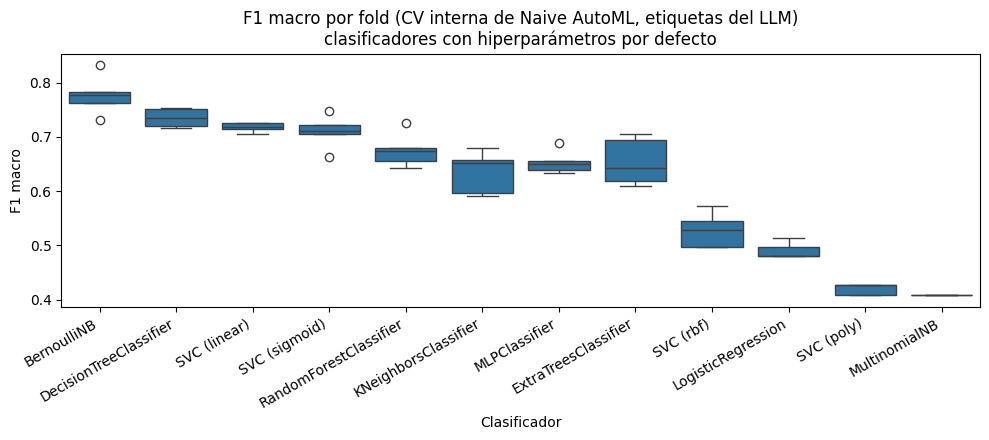

In [30]:
import re, ast
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

hist = naml.history.copy()
hist = hist[hist["status"] == "ok"]

# Solo clasificadores con hiperparámetros por defecto y sin preprocesadores
base = hist[(hist["default_hp"] == True)
            & hist["data-pre-processor_class"].isna()
            & hist["feature-pre-processor_class"].isna()]

def nombre_modelo(r):
    n = r["learner_class"].split(".")[-1]
    if n == "SVC":                                   # separar SVC por kernel
        k = re.search(r"kernel='(\w+)'", str(r["pipeline"]))
        n += f" ({k.group(1) if k else 'rbf'})"
    return n

largo = [{"Clasificador": nombre_modelo(r), "F1 macro": f}
         for _, r in base.iterrows()
         for f in (ast.literal_eval(r["evaluation_report"]) if isinstance(r["evaluation_report"], str)
                   else r["evaluation_report"])["f1_macro"]]

df_box = pd.DataFrame(largo)
orden = df_box.groupby("Clasificador")["F1 macro"].median().sort_values(ascending=False).index

plt.figure(figsize=(10, 4.5))
sns.boxplot(data=df_box, x="Clasificador", y="F1 macro", order=orden)
plt.xticks(rotation=30, ha="right")
plt.title("F1 macro por fold (CV interna de Naive AutoML, etiquetas del LLM)\n"
          "clasificadores con hiperparámetros por defecto")
plt.tight_layout()
plt.savefig("boxplot_clasificadores.png", dpi=200, bbox_inches="tight")
plt.show()

In [31]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import Normalizer
from sklearn.naive_bayes import BernoulliNB

def crear_pipeline():
    """Modelo final: TF-IDF con números (1-3 gramas, min_df=3) + Normalizer + BernoulliNB (elegido por el AutoML)."""
    return Pipeline([
        ("tfidf", TfidfVectorizer(ngram_range=(1, 3), min_df=3)),
        ("norm",  Normalizer()),
        ("nb",    BernoulliNB()),
    ])

In [32]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import (f1_score, roc_auc_score, RocCurveDisplay,
                             ConfusionMatrixDisplay, confusion_matrix)

Xtr, Xva, Xte = X_train.fillna(""), X_val.fillna(""), X_test.fillna("")

# Modelo final: SOLO train (etiquetas LLM)
final = crear_pipeline().fit(Xtr, y_train)

AUC val: 0.964 | AUC test: 0.906


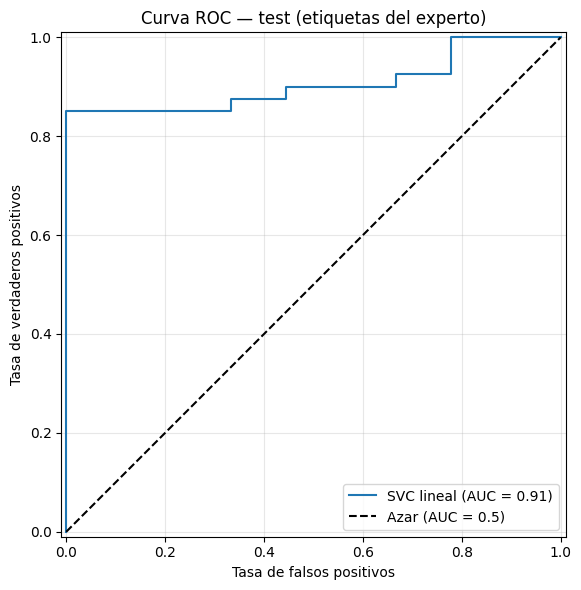

In [34]:
score_te = final.predict_proba(Xte)[:, 1]  # SVC sin probabilidades: se usa el puntaje de decisión
auc_te = roc_auc_score(y_test, score_te)
auc_va = roc_auc_score(y_val, final.predict_proba(Xva)[:, 1])
print(f"AUC val: {auc_va:.3f} | AUC test: {auc_te:.3f}")

fig, ax = plt.subplots(figsize=(6, 6))
RocCurveDisplay.from_predictions(y_test, score_te, ax=ax, name="SVC lineal")   # el AUC lo agrega solo
ax.plot([0, 1], [0, 1], "k--", label="Azar (AUC = 0.5)")
ax.set(title="Curva ROC — test (etiquetas del experto)",
       xlabel="Tasa de falsos positivos", ylabel="Tasa de verdaderos positivos")
ax.legend(loc="lower right"); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig("curva_roc_test.png", dpi=200, bbox_inches="tight"); plt.show()

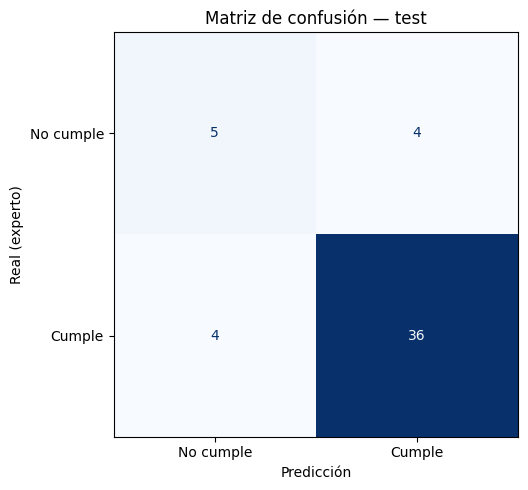

In [35]:
pred_te = final.predict(Xte)

fig, ax = plt.subplots(figsize=(5.5, 5))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred_te, labels=[0, 1]),
                       display_labels=["No cumple", "Cumple"]).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set(title="Matriz de confusión — test", xlabel="Predicción", ylabel="Real (experto)")
plt.tight_layout(); plt.savefig("matriz_confusion_test.png", dpi=200, bbox_inches="tight"); plt.show()

In [3]:
df_train

,caso,nota,examen_fisico_few,Texto_g
98,S1139-76322009000700014-2,Paciente de 14 años que acude a la consulta po...,1,paciente de 14 años que acude a la consulta po...
99,S0213-12852005000400003-1,"Paciente varón, de 47 años, casado, acude al d...",1,paciente varón de 47 años casado acude al depa...
100,S0212-71992000001200006-1,"Varón de 49 años, peruano con 10 años de resid...",1,varón de 49 años peruano con 10 años de reside...
101,S1130-14732009000300006-1,Una mujer de 26 años sin antecedentes neurológ...,1,una mujer de 26 años sin antecedentes neurológ...
102,S0365-66912009000100008-1,Paciente varón de 28 años de edad que sufre un...,1,paciente varón de 28 años de edad que sufre un...
...,...,...,...,...
992,S1130-01082009000700016-1,Presentamos el caso de un paciente de 77 años ...,0,presentamos el caso de un paciente de 77 años ...
993,S0210-48062009000300013-3,Varón de 74 años\nAntecedentes personales: HTA...,0,varón de 74 años antecedentes personales hta e...
994,S0004-06142006000900009-1,Paciente de 26 años que es remitido desde las ...,0,paciente de 26 años que es remitido desde las ...
995,S1130-01082005001100016-1,Mujer de 59 años sin antecedentes de interés q...,1,mujer de 59 años sin antecedentes de interés q...


In [79]:
### guarda en caso de caida del kernel

import os, types, dill

def guardar_sesion(ruta='resultados/sesion.pkl'):
    os.makedirs(os.path.dirname(ruta), exist_ok=True)
    datos, omitidas = {}, []
    for nombre, valor in list(globals().items()):
        # saltar variables internas, módulos y cosas de Jupyter
        if nombre.startswith('_') or isinstance(valor, types.ModuleType) \
           or nombre in ('In', 'Out', 'exit', 'quit', 'get_ipython'):
            continue
        try:
            dill.dumps(valor)      # prueba si se puede guardar
            datos[nombre] = valor
        except Exception:
            omitidas.append(nombre)
    with open(ruta, 'wb') as f:
        dill.dump(datos, f)
    print(f'Guardadas {len(datos)} variables.')
    if omitidas:
        print('No se pudieron guardar:', omitidas)


guardar_sesion()

Guardadas 189 variables.


In [2]:
### Carga en caso de caida del kernel

import dill

def cargar_sesion(ruta='resultados/sesion.pkl'):
    with open(ruta, 'rb') as f:
        globals().update(dill.load(f))
    print('Sesión restaurada.')

cargar_sesion()

Sesión restaurada.
